In [2]:
%pip install "gymnasium" "stable-baselines3" "numpy" "matplotlib"

  Using cached gymnasium-1.4.0-py3-none-any.whl.metadata (9.0 kB)
  Using cached stable_baselines3-2.9.0-py3-none-any.whl.metadata (5.0 kB)
  Using cached farama_notifications-0.0.6-py3-none-any.whl.metadata (729 bytes)
  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
Using cached gymnasium-1.4.0-py3-none-any.whl (476 kB)
Using cached stable_baselines3-2.9.0-py3-none-any.whl (187 kB)
Using cached farama_notifications-0.0.6-py3-none-any.whl (2.9 kB)
Using cached torch-2.14.1-cp312-cp312-win_amd64.whl (124.1 MB)
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.11.0
    Uninstalling typing_extensions-4.11.0:
      Successfully uninstalled typing_extensions-4.11.0
  Attempting uninstall: 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from IPython.display import Image

## The layout do mapa

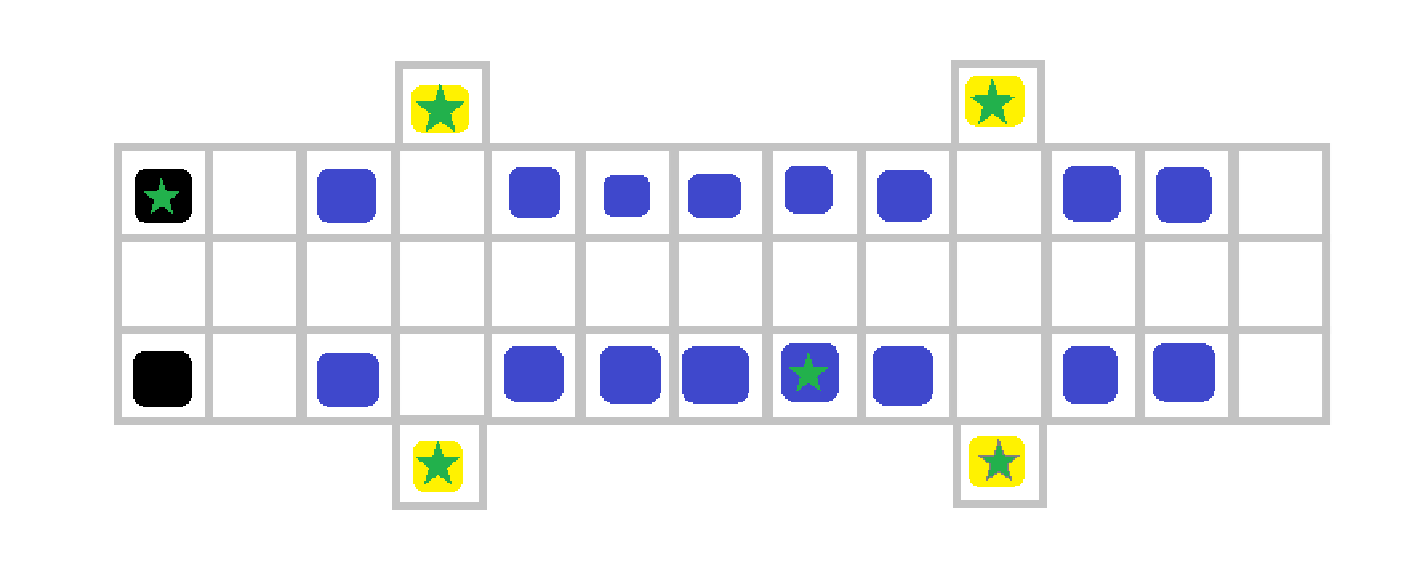

In [8]:
Image(filename='map.png', width=500, height=500)

1. Quadrado azul: assentos do aviao;  
2. Quadrado preto: assentos dos pilotos;  
3. Quadrado amarelo: saidas;  
4. Estrelas verdes: objetos pegaveis/interagiveis;  

### Regras de movimento:

1. A chance de passar por cima de um obstaculo é de 0.2 e decresce linearmente a cada obstaculo que o agente passa por cima;
2. Para pegar um objeto, o agente precisa estar na mesma posicao que o objeto e executar a acao de pegar;
3. Para largar um objeto, basta o agente executar a acao de largar;
4. O agente so consegue segurar um objeto por vez;
5. Para abrir a porta de saida, o agente precisa estar na mesma posicao que a saida e executar a acao de abrir com o objeto correto na mao;

In [ ]:
class CabinEnv(gym.Env):

    def __init__(self):
        super().__init__()

        # 1 lugar andavel, 0 nao existe 
        self.world_map = np.array([
            [0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        ])

        self.height, self.width = self.world_map.shape
        self.max_steps = 150

        # ACOES: cima, baixo, esq, dir, pegar, largar e abrir porta
        self.action_space = spaces.Discrete(7)

        self.start_pos = np.array([8, 1], dtype=np.int32)
        self.agent_pos = self.start_pos.copy()

        #TODO: define the reward system using a reward function

        # defining what the agent can observe
        self.observation_space = spaces.Box(
            low=np.array([0, 0]), 
            high=np.array([self.height - 1, self.width - 1]), 
            shape=(2,), 
            dtype=np.int32
        )

        # obstaculos = assentos
        self.obstacles = {
            (0, 1), (2, 1), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (10, 1), (11, 1),
            (0, 3), (2, 3), (4, 3), (5, 3), (6, 3), (7, 3), (8, 3), (10, 3), (11, 3),
        }

        # stating where the target and exit are located in the cabin (change it later if we want)
        self.target = (9, 0)
        self.exit = { (3, 0) , (3, 4), (9, 0), (9, 4) }

    def _get_obs(self):
        return np.array([
            self.agent_pos[0],
            self.agent_pos[1],
            int(self.inspected),
            self.max_steps - self.steps
        ], dtype=np.int32)

    # resetting the environment to its initial state
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.agent_pos = self.start_pos.copy()
        self.inspected = False
        self.steps = 0

        return self._get_obs(), {}

    # defining the step function which takes an action and returns the next state, reward, and whether the episode is done
    def step(self, action):
        self.steps += 1
        reward = -0.1

        # TODO: Implement the reward function based on the agent's actions and the environment state

        # Candidate movement
        moves = {
            0: (0, 1),  # up
            1: (0, -1),   # down
            2: (1, 0),  # left
            3: (-1, 0)    # right
        }

        if action in moves:
            dx, dy = moves[action]
            nx, ny = self.agent_pos[0] + dx, self.agent_pos[1] + dy

            # Stay in the cabin boundaries
            if not (0 <= nx < self.width and
                    0 <= ny < self.height):
                reward -= 2

            # Do not pass through obstacles
            elif (nx, ny) in self.obstacles:
                reward -= 2

            else:
                self.agent_pos[0], self.agent_pos[1] = nx, ny

        # Inspect the target location
        elif action == 4:
            if (self.agent_pos[0], self.agent_pos[1]) == self.target:
                if not self.inspected:
                    self.inspected = True
                    reward += 10
            else:
                reward -= 0.5

        # Finish only after completing the task
        # and reaching the designated exit
        terminated = (
            self.inspected
            and (self.agent_pos[0], self.agent_pos[1]) in self.exit
        )

        #reward function is not yet implemented
        if terminated:
            reward += 50

        truncated = self.steps >= self.max_steps

        return (
            self._get_obs(),
            reward,
            terminated,
            truncated,
            {}
        )


In [ ]:
from gymnasium.utils.env_checker import check_env

#creating and testing the cabin env
env = CabinEnv()

check_env(env)
obs, info = env.reset(seed=42)

print("Observation shape:", obs.shape)
print("Available actions:", env.action_space)
print(env.render())


#TODO: train the agent using an RL algorithm (e.g., DQN, PPO) and evaluate its performance in the CabinEnv.
#TODO: Implement the reward function
#TODO: visually implement the environment using a library like Pygame or Matplotlib to visualize the agent's movements and interactions with the cabin.
